# Quanto rende la pubblicità?

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Lezione 2*

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vincnardelli/msd/blob/main/codice/2/regressione_advertising.ipynb)

Il codice dietro le slide della lezione 2.
`advertising.csv` contiene, per 200 mercati, il budget pubblicitario su TV, radio e giornali (`TV`, `radio`, `newspaper`, migliaia di \$) e le vendite (`sales`, migliaia di unità).

In [1]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf

In [2]:
adv = pl.read_csv("https://www.vincnardelli.com/msd/dati/advertising.csv")
adv.head()

TV,radio,newspaper,sales
f64,f64,f64,f64
230.1,37.8,69.2,22.1
44.5,39.3,45.1,10.4
17.2,45.9,69.3,9.3
151.5,41.3,58.5,18.5
180.8,10.8,58.4,12.9


### 1. La retta dei minimi quadrati: vendite e budget TV

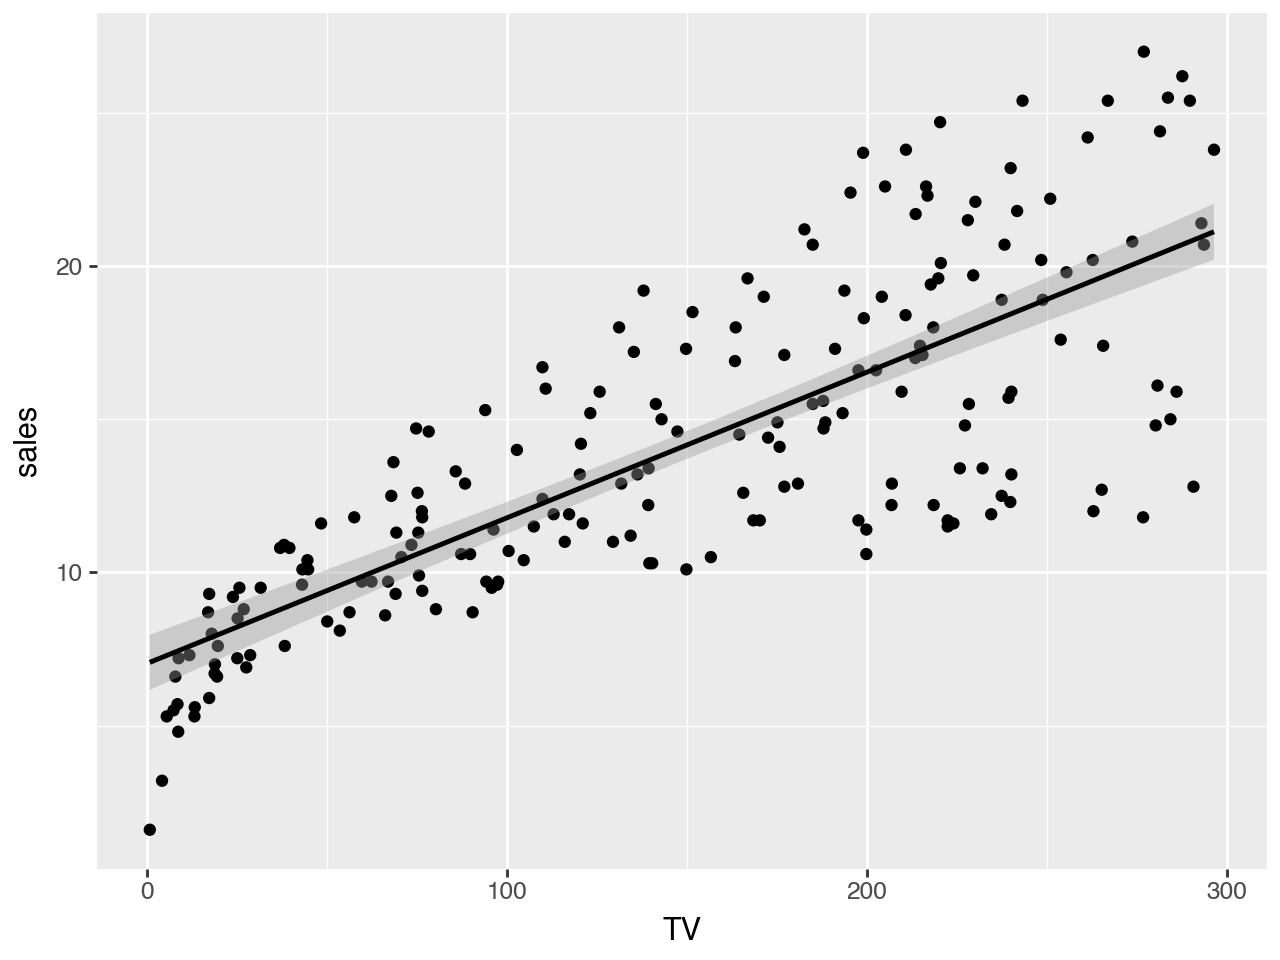

In [3]:
ggplot(adv, aes(x="TV", y="sales")) + geom_point() + geom_smooth(method="lm")

In [4]:
modello = smf.ols("sales ~ TV", data=adv).fit()
modello.params

Intercept    7.032594
TV           0.047537
dtype: float64

### 2. La tabella dei risultati: errori standard, t, p-value, intervalli, $R^2$

In [5]:
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.47e-42
Time:                        12:50:22   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.0326      0.458     15.360      0.000       6.130       7.935
TV             0.0475      0.003     17.668      0.000       0.042       0.053
==============================================================================
Omnibus:                        0.531   Durbin-Watson:                   1.935
Prob(Omnibus):                  0.767   Jarque-Bera (JB):                0.669
Skew:                          -0.089   Prob(JB):                        0.716
Kurtosis:                       2.779   Cond. No.                         338.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [6]:
modello.conf_int()

,0,1
Intercept,6.129719,7.935468
TV,0.042231,0.052843


In [7]:
modello.rsquared

0.6118750508500712

### 3. Prevedere, con i due intervalli: la media (`mean_ci`) e il singolo mercato (`obs_ci`)

In [8]:
modello.get_prediction({"TV": [0, 100, 200, 400]}).summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,7.032594,0.457843,6.129719,7.935468,0.543349,13.521838
1,11.786258,0.262897,11.267820,12.304695,5.339251,18.233264
2,16.539922,0.270919,16.005665,17.074178,10.091624,22.988219
3,26.047250,0.718556,24.630244,27.464255,19.466747,32.627753


### 4. Il paradosso dei giornali: da soli contano, insieme agli altri no

In [9]:
giornali = smf.ols("sales ~ newspaper", data=adv).fit()
giornali.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                  0.047
Method:                 Least Squares   F-statistic:                     10.89
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00115
Time:                        12:50:22   Log-Likelihood:                -608.34
No. Observations:                 200   AIC:                             1221.
Df Residuals:                     198   BIC:                             1227.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.3514      0.621     19.876      0.000      11.126      13.577
newspaper      0.0547      0.017      3.300      0.001       0.022       0.087
==============================================================================
Omnibus:                        6.231   Durbin-Watson:                   1.983
Prob(Omnibus):                  0.044   Jarque-Bera (JB):                5.483
Skew:                           0.330   Prob(JB):                       0.0645
Kurtosis:                       2.527   Cond. No.                         64.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [10]:
multiplo = smf.ols("sales ~ TV + radio + newspaper", data=adv).fit()
multiplo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        12:50:22   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
radio          0.1885      0.009     21.893      0.000       0.172       0.206
newspaper     -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [11]:
adv.corr()

TV,radio,newspaper,sales
f64,f64,f64,f64
1.0,0.054809,0.056648,0.782224
0.054809,1.0,0.354104,0.576223
0.056648,0.354104,1.0,0.228299
0.782224,0.576223,0.228299,1.0


### 5. $R^2$ aggiustato: senza i giornali il modello migliora

In [12]:
senza = smf.ols("sales ~ TV + radio", data=adv).fit()
senza.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     859.6
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           4.83e-98
Time:                        12:50:22   Log-Likelihood:                -386.20
No. Observations:                 200   AIC:                             778.4
Df Residuals:                     197   BIC:                             788.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9211      0.294      9.919      0.000       2.340       3.502
TV             0.0458      0.001     32.909      0.000       0.043       0.048
radio          0.1880      0.008     23.382      0.000       0.172       0.204
==============================================================================
Omnibus:                       60.022   Durbin-Watson:                   2.081
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              148.679
Skew:                          -1.323   Prob(JB):                     5.19e-33
Kurtosis:                       6.292   Cond. No.                         425.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""